# 04 — Testes Estatísticos e Comparação Final

Este notebook realiza a validação estatística da diferença de desempenho entre a Regressão Logística e o BERTimbau.

**O que será feito:**
1. **Teste de McNemar:** Verifica se a proporção de acertos/erros entre os modelos é estatisticamente diferente (p-valor < 0.05).
2. **Bootstrap (1000 iterações):** Calcula o Intervalo de Confiança (IC 95%) para o F1-Score de cada modelo.
3. **Gráfico Comparativo:** Plota as barras com as margens de erro do IC 95%.

> ⚠️ **Premissa:** Requer os arquivos `preds_rl.csv` e `preds_bert.csv` gerados nos notebooks 02 e 03.

## 1. Setup e Carregamento

In [1]:
import sys
import os
import glob
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import f1_score
from statsmodels.stats.contingency_tables import mcnemar
from datasets import load_from_disk
from IPython.display import display

# --- CORREÇÃO DEFINITIVA DO PATH ---
arquivos_utils = glob.glob("/content/**/src/utils.py", recursive=True)
if arquivos_utils:
    caminho_utils = Path(arquivos_utils[0])
    caminho_src = caminho_utils.parent
    raiz_projeto = caminho_src.parent
    if str(caminho_src) not in sys.path:
        sys.path.insert(0, str(caminho_src))
    print(f"✅ Ambiente configurado. Raiz: {raiz_projeto}")
else:
    raise FileNotFoundError("Não foi possível encontrar o src/utils.py")

from utils import setup_logging, ensure_dir, load_results

sns.set_theme(style="whitegrid")
logger = setup_logging(name="testes_estatisticos")

✅ Ambiente configurado. Raiz: /content/Classifica-o-de-Discurso-T-xico-em-Redes-Sociais


In [2]:
# Caminhos dos arquivos
metrics_dir = raiz_projeto / "results" / "metrics"
figures_dir = raiz_projeto / "results" / "figures"
ensure_dir(figures_dir)

# 1. Carregando o y_true (rótulos reais do teste)
dataset_path = raiz_projeto / "data" / "processed" / "told-br-binary-clean"
ds = load_from_disk(str(dataset_path))
y_true = np.array(ds["test"]["label"])

# 2. Carregando as predições dos modelos
try:
    y_pred_rl = pd.read_csv(metrics_dir / "preds_rl.csv").iloc[:, 0].values
    y_pred_bert = pd.read_csv(metrics_dir / "preds_bert.csv").iloc[:, 0].values
    print("✅ Predições carregadas com sucesso!")
except FileNotFoundError as e:
    print("❌ ERRO: Arquivos de predições não encontrados.")
    print("Certifique-se de que rodou as células 'Salvar as predições' nos notebooks 02 e 03.")
    raise e

# 3. Carregando os JSONs de métricas
rl_data = load_results(metrics_dir / "baseline_rl_metrics.json")
bert_data = load_results(metrics_dir / "bertimbau_metrics.json")

print(f"Total de amostras no teste: {len(y_true)}")
print(f"Predições RL: {len(y_pred_rl)} | Predições BERT: {len(y_pred_bert)}")

✅ Predições carregadas com sucesso!
Total de amostras no teste: 2100
Predições RL: 2100 | Predições BERT: 2100


## 2. Teste de McNemar

O teste de McNemar avalia se a discordância entre os modelos é estatisticamente significativa. Ele compara os casos em que um modelo acertou e o outro errou.

In [3]:
# Criando a matriz de acertos/erros
acerto_rl = (y_pred_rl == y_true)
acerto_bert = (y_pred_bert == y_true)

# Contagens para a tabela de contingência
a = np.sum(acerto_rl & acerto_bert)      # Ambos acertaram
b = np.sum(acerto_rl & ~acerto_bert)     # Só a RL acertou
c = np.sum(~acerto_rl & acerto_bert)     # Só o BERT acertou
d = np.sum(~acerto_rl & ~acerto_bert)    # Ambos erraram

tabela_contingencia = [[a, b], [c, d]]

# Rodando o teste
resultado_mcnemar = mcnemar(tabela_contingencia, exact=True)
p_valor = resultado_mcnemar.pvalue

print("=" * 50)
print("RESULTADO DO TESTE DE MCNEMAR")
print("=" * 50)
print(f"Ambos acertaram: {a} casos")
print(f"Apenas RL acertou: {b} casos")
print(f"Apenas BERTimbau acertou: {c} casos")
print(f"Ambos erraram: {d} casos")
print("-" * 50)
print(f"P-valor: {p_valor:.5e}")

if p_valor < 0.05:
    print("\n✅ Conclusão: A diferença de desempenho é ESTATISTICAMENTE SIGNIFICATIVA (p < 0.05).")
else:
    print("\n❌ Conclusão: Não há evidências suficientes para afirmar que os modelos são diferentes (p >= 0.05).")
print("=" * 50)

RESULTADO DO TESTE DE MCNEMAR
Ambos acertaram: 1376 casos
Apenas RL acertou: 147 casos
Apenas BERTimbau acertou: 247 casos
Ambos erraram: 330 casos
--------------------------------------------------
P-valor: 5.34966e-07

✅ Conclusão: A diferença de desempenho é ESTATISTICAMENTE SIGNIFICATIVA (p < 0.05).


## 3. Intervalo de Confiança via Bootstrap

Vamos reamostrar os dados 1.000 vezes para estimar a margem de erro do F1-Score de cada modelo.

In [4]:
def bootstrap_f1_ci(y_true, y_pred, n_bootstraps=1000, alpha=0.05):
    rng = np.random.default_rng(42)
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    n_samples = len(y_true)
    
    f1_scores = []
    for _ in range(n_bootstraps):
        indices = rng.integers(0, n_samples, n_samples)
        if len(np.unique(y_true[indices])) < 2:
            continue
        score = f1_score(y_true[indices], y_pred[indices], average='binary', zero_division=0)
        f1_scores.append(score)
        
    lower = np.percentile(f1_scores, alpha/2 * 100)
    upper = np.percentile(f1_scores, (1 - alpha/2) * 100)
    return float(lower), float(upper), f1_scores

# Rodando para a Regressão Logística
rl_lower, rl_upper, rl_boot_scores = bootstrap_f1_ci(y_true, y_pred_rl)
rl_f1_real = f1_score(y_true, y_pred_rl, average='binary')

# Rodando para o BERTimbau
bert_lower, bert_upper, bert_boot_scores = bootstrap_f1_ci(y_true, y_pred_bert)
bert_f1_real = f1_score(y_true, y_pred_bert, average='binary')

print(f"Regressão Logística: F1 = {rl_f1_real:.4f} | IC 95%: [{rl_lower:.4f} - {rl_upper:.4f}]")
print(f"BERTimbau:           F1 = {bert_f1_real:.4f} | IC 95%: [{bert_lower:.4f} - {bert_upper:.4f}]")

Regressão Logística: F1 = 0.7018 | IC 95%: [0.6779 - 0.7241]
BERTimbau:           F1 = 0.7749 | IC 95%: [0.7543 - 0.7937]


## 4. Visualização Comparativa

Gráfico de barras com as margens de erro obtidas pelo Bootstrap.

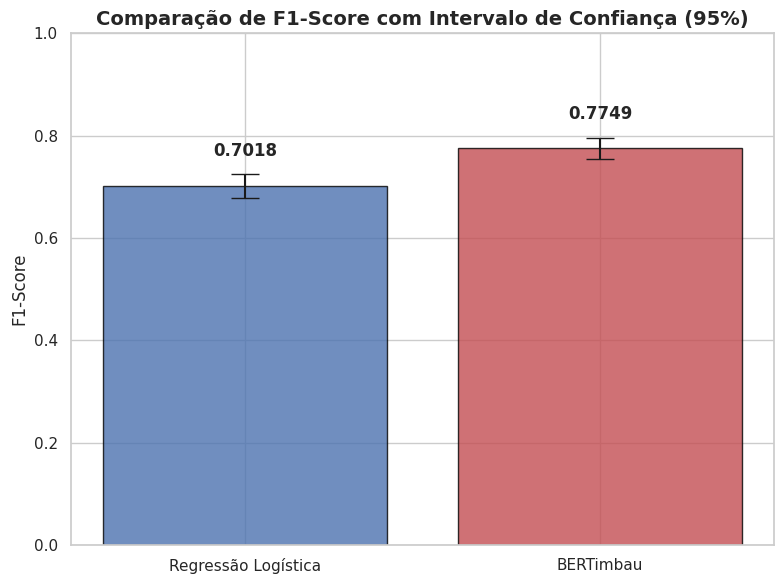

✅ Gráfico salvo em: /content/Classifica-o-de-Discurso-T-xico-em-Redes-Sociais/results/figures/04_comparacao_ic95.png


In [5]:
# Preparando dados para o gráfico
modelos = ['Regressão Logística', 'BERTimbau']
f1_scores = [rl_f1_real, bert_f1_real]
erros = [rl_f1_real - rl_lower, bert_f1_real - bert_lower] # Margem de erro (para baixo)

plt.figure(figsize=(8, 6))

# Criando as barras com barras de erro (yerr)
barras = plt.bar(modelos, f1_scores, yerr=erros, capsize=10, 
                 color=['#4C72B0', '#C44E52'], alpha=0.8, edgecolor='black')

plt.title('Comparação de F1-Score com Intervalo de Confiança (95%)', fontsize=14, fontweight='bold')
plt.ylabel('F1-Score')
plt.ylim(0, 1.0)

# Adicionando os valores exatos acima das barras
for i, barra in enumerate(barras):
    yval = barra.get_height()
    plt.text(barra.get_x() + barra.get_width()/2, yval + 0.05, 
             f"{yval:.4f}", ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
fig_path = figures_dir / '04_comparacao_ic95.png'
plt.savefig(fig_path, dpi=300, bbox_inches='tight')
plt.show()

print(f"✅ Gráfico salvo em: {fig_path}")

## 5. Download dos Resultados

In [6]:
import shutil
from google.colab import files

# Compacta a pasta de figuras
archive_path = shutil.make_archive("/content/figuras_estatisticas", "zip", str(figures_dir))
print(f"Baixando: {archive_path}")
files.download(archive_path)

# Salva a tabela final em CSV
df_final = pd.DataFrame({
    'Modelo': modelos,
    'F1-Score': f1_scores,
    'IC 95% (Min)': [rl_lower, bert_lower],
    'IC 95% (Max)': [rl_upper, bert_upper]
})
df_final.to_csv(metrics_dir / "tabela_final_comparativa.csv", index=False)
print("✅ Tabela final salva em results/metrics/tabela_final_comparativa.csv")

Baixando: /content/figuras_estatisticas.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

✅ Tabela final salva em results/metrics/tabela_final_comparativa.csv
